# Google Hackathon · STEP 5 Test other demand
### DADS5250 · Generative AI & LangChain · Monthly staffing plans for 2026

**Inputs:** Use `countries.csv`, `forecast_2026.csv`, and the simulator from Step 3, and 2 staffing mode (plan) from Step 4

**Scenarios:**
1. **Low demand:** 20% below the original forecast.
2. **Base demand:** Original forecast.
3. **High demand:** 20% above the original forecast.

**Modes:** Keep current staff, Profit only, and Profit with SLA.

**Method:** Keep monthly hiring and release decisions fixed. Change demand and replay each plan through the simulator without running the optimizer again.

**Outputs:** Country-level scenario results and an overall comparison of modeled profit, staffing costs, service rates, abandonment, and year-end backlog.

In [3]:
%pip install -q langchain-core langchain-openai

In [4]:
from google.colab import files

uploaded = files.upload()

Saving countries.csv to countries.csv
Saving forecast_2026.csv to forecast_2026.csv


In [5]:
# Google Colab: upload the two input datasets (CSV files stay separate).
# Your computer may show names such as countries(2).csv and forecast_2026(2).csv.
# This cell standardizes them INSIDE Colab to countries.csv and forecast_2026.csv.
from pathlib import Path
import re
import shutil

DATA_FOLDER = Path('/content') if Path('/content').is_dir() else Path.cwd()
REQUIRED_CSVS = ('countries.csv', 'forecast_2026.csv')

def standard_name(filename):
    """Discard only the duplicate-download suffix, e.g. countries(2).csv -> countries.csv."""
    m = re.fullmatch(r'(countries|forecast_2026)\s*(?:\(\d+\))?\.csv',
                     Path(filename).name, flags=re.IGNORECASE)
    return f'{m.group(1).lower()}.csv' if m else None

def normalize_uploads(directory=DATA_FOLDER):
    """Use the selected CSVs without modifying files on the user's computer."""
    for canonical in REQUIRED_CSVS:
        target = directory / canonical
        if target.is_file():
            continue
        candidates = [f for f in directory.glob('*.csv')
                      if standard_name(f.name) == canonical]
        if not candidates:
            continue
        # If several duplicate-download versions exist, use the newest uploaded version.
        source = max(candidates, key=lambda p: p.stat().st_mtime_ns)
        shutil.copyfile(source, target)
        print(f'Using {source.name} as {canonical}')

normalize_uploads()
missing = [name for name in REQUIRED_CSVS if not (DATA_FOLDER / name).is_file()]
if missing:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Place the required files in {DATA_FOLDER}: {missing}')
    print('Select TWO files: one countries CSV and one forecast_2026 CSV.')
    uploaded = files.upload()
    selected = [standard_name(name) for name in uploaded]
    selected = [name for name in selected if name in REQUIRED_CSVS]
    if len(selected) != len(set(selected)):
        raise ValueError('More than one copy of the same dataset selected. Upload one countries file and one forecast file.')
    # Colab stores uploaded files in the current working directory.
    for original, content in uploaded.items():
        canonical = standard_name(original)
        if canonical is not None:
            (DATA_FOLDER / canonical).write_bytes(content)
    normalize_uploads()

missing = [name for name in REQUIRED_CSVS if not (DATA_FOLDER / name).is_file()]
if missing:
    raise FileNotFoundError(f'Missing required CSV(s): {missing}. Re-run this cell and upload the missing file(s).')
print('Ready! Step 3 uses exactly these two data files:')
for name in REQUIRED_CSVS:
    print(' -', DATA_FOLDER / name)


Ready! Step 3 uses exactly these two data files:
 - /content/countries.csv
 - /content/forecast_2026.csv


In [6]:
from pathlib import Path
from dataclasses import dataclass
from collections import deque
import os, json, math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PATHS = [Path('.'), Path('data/clean'), Path('/content'), Path('/mnt/data')]
def locate(filename):
    for folder in PATHS:
        path = folder / filename
        if path.is_file():
            return path
    raise FileNotFoundError(f"Could not find {filename}. Run the Colab upload cell above.")

countries = pd.read_csv(locate('countries.csv'))
forecast = pd.read_csv(locate('forecast_2026.csv'))
required_a = {'Country','Existing_Agent_Count','Annual_Agent_Salary_USD'}
required_b = {'Country','Month','Forecast_Eligible_Signups','Avg_Budget'}
assert required_a.issubset(countries), required_a-set(countries)
assert required_b.issubset(forecast), required_b-set(forecast)
assert not countries.Country.duplicated().any()
assert not forecast[['Country','Month']].duplicated().any()
assert set(forecast.Country)==set(countries.Country)
assert len(forecast)==len(countries)*12
assert (forecast.groupby('Country').Month.nunique()==12).all()
assert (forecast[['Forecast_Eligible_Signups','Avg_Budget']]>=0).all().all()
assert (countries[['Existing_Agent_Count','Annual_Agent_Salary_USD']]>=0).all().all()
inputs = forecast.merge(countries[['Country','Existing_Agent_Count','Annual_Agent_Salary_USD']], on='Country',validate='many_to_one').sort_values(['Country','Month'])
print(f'Loaded {len(countries)} countries, {len(inputs)} country-month records, {inputs.Forecast_Eligible_Signups.sum():,.0f} expected eligible sign-ups.')
display(inputs.head())

Loaded 22 countries, 264 country-month records, 106,167 expected eligible sign-ups.


,Country,Month,Forecast_Eligible_Signups,Avg_Budget,Existing_Agent_Count,Annual_Agent_Salary_USD
0,Argentina,1,70.8,11131.83,200,18687
1,Argentina,2,68.2,11131.83,200,18687
2,Argentina,3,69.1,11131.83,200,18687
3,Argentina,4,68.7,11131.83,200,18687
4,Argentina,5,68.3,11131.83,200,18687


## 1 · Business rules and assumptions


*Assumed revenue proxy:* each advertiser that completes onboarding contributes `Avg_Budget × capture_rate / 12` for each month remaining in 2026. Advertiser **budget is not Google's revenue**; `capture_rate` is a hypothetical take-rate used only for demonstration. Existing staffing cost is shown on an allocated basis (20% of existing team time).

**Revised modeling note:** An advertiser served in a particular month retains the revenue contribution associated with its original forecast cohort; we do not apply a later month's average budget to every previously served advertiser. Advertiser churn and true take rates remain unknown.


**Optimization objective:** maximize the sum of modeled 2026 monthly revenue minus allocated salaries and hiring costs. An unconstrained optimizer may choose to leave customers waiting if serving them would cost more than the estimated revenue; an optional **minimum annual service rate** provides an explicit service-quality constraint. Revenue is credited only after sign-ups are actually served; cohort budgets do not change after onboarding. The model uses 2026 recurring revenue only—future years, severance, training, and customer lifetime value are out of scope.


In [7]:
@dataclass(frozen=True)
class GameRules:
    cases_per_agent_month: float = 10.0   # illustration only
    existing_time_share: float = 0.20      # fraction existing agents can use for onboarding
    hire_lead_months: int = 1             # start next month after an order
    max_wait_months: int = 2              # FIFO waiting limit; abandon at start of later month
    hire_fee_fraction: float = 0.08       # one-off 8% annual salary / hire at activation
    revenue_capture_rate: float = 0.10    # not a verified Google take rate
    max_hires_per_month: int = 150        # format/absolute safety guardrail
    capacity_buffer: float = 0.10        # assumed demand cushion (illustrative, 10%)
RULES = GameRules()

# Example run: one country = 12 decision rounds / 12 LLM calls; change to any name in countries.Country.
DEMO_COUNTRY = 'USA'
assert DEMO_COUNTRY in set(countries.Country)
print('Rules:', RULES)
print('Available countries:', ', '.join(countries.Country.tolist()))

Rules: GameRules(cases_per_agent_month=10.0, existing_time_share=0.2, hire_lead_months=1, max_wait_months=2, hire_fee_fraction=0.08, revenue_capture_rate=0.1, max_hires_per_month=150, capacity_buffer=0.1)
Available countries: USA, UK, Germany, India, Brazil, Japan, Australia, Canada, France, Mexico, China, Italy, Spain, Poland, South Korea, South Africa, Vietnam, Argentina, Turkey, Indonesia, Thailand, UAE


## 2 · Decision contract: what can GenAI control?

Exactly like the Beer Game's order quantity, the LLM controls **how many flexible staff to order (`hire`) and how many *active flexible* staff to release (`release`) in the current month**. It cannot change the forecast, annual salary, backlog, service capacity, or financial formulas.

**No looking ahead:** The prompt includes the current month's *forecast*, past observed arrivals, hiring pipeline, and backlog, **not** current-month realized arrivals, which are revealed *after* the decision. The same 2026 demand is used for every decision approach.

**Safety:** Numeric validation rejects negative/noninteger decisions and other malformed actions. A separate **economic capacity guardrail** caps requested hires at a forecast-supported shortfall, prevents releasing capacity needed for predicted demand, and prevents hires that arrive after 2026. Raw suggestions are saved alongside applied decisions. Invalid model replies become a clearly logged **no-change fallback**, not a fabricated valid LLM decision.

In [8]:
def check_action(proposed, observed, rules=RULES):
    if not isinstance(proposed, dict): raise ValueError('Decision must be a JSON object')
    hire, release = proposed.get('hire'), proposed.get('release')
    if type(hire) is not int or type(release) is not int: raise ValueError('hire and release must be integers')
    if min(hire,release)<0: raise ValueError('No negative actions')
    if hire>rules.max_hires_per_month: raise ValueError('Hires exceed safe maximum')
    if release>observed['active_flexible_agents']: raise ValueError('Releases exceed active flexible staff')
    if hire and release: raise ValueError('Cannot hire and release in same month')
    return {'hire':hire,'release':release,'reason':str(proposed.get('reason',''))[:1500]}

def augment_capacity_state(observed, rules=RULES):
    """Show the LLM mathematically derived capacity and financially relevant limits.

    Uses known forecasts, not realized future demand. The 10% buffer is an
    explicitly stated scenario assumption, NOT a Google policy.
    """
    state = dict(observed)
    current_agents = float(state['existing_agents'])*rules.existing_time_share + int(state['active_flexible_agents'])
    pending_next = int(state['pending_hires'].get(str(state['month']+1), 0))
    capacity_now = current_agents * rules.cases_per_agent_month
    capacity_next_before_new = (current_agents + pending_next) * rules.cases_per_agent_month
    forecast_next = state.get('forecast_next_month')
    backlog = int(state['backlog_start'])
    target_today = (float(state['forecast_this_month']) + backlog)*(1+rules.capacity_buffer)
    target_next = ((float(forecast_next) + backlog)*(1+rules.capacity_buffer)
                   if forecast_next is not None else 0.0)
    hires_shortfall = max(0, math.ceil((target_next-capacity_next_before_new)/rules.cases_per_agent_month-1e-9))
    if state['month'] + rules.hire_lead_months > 12:
        hires_shortfall = 0
    # Releasing active staff must not create a shortfall this month or next month.
    required_today_flex = max(0, math.ceil((target_today/rules.cases_per_agent_month)
                                       - float(state['existing_agents'])*rules.existing_time_share - 1e-9))
    required_next_flex = max(0, math.ceil((target_next/rules.cases_per_agent_month)
                                      - float(state['existing_agents'])*rules.existing_time_share - pending_next - 1e-9))
    max_safe_release = max(0, int(state['active_flexible_agents'])-max(required_today_flex,required_next_flex))
    state.update({
        'current_capacity_cases': int(math.floor(capacity_now)),
        'projected_next_month_capacity_before_new_hires': int(math.floor(capacity_next_before_new)),
        'next_month_target_with_buffer': round(target_next, 2) if forecast_next is not None else None,
        'max_justified_hires': min(rules.max_hires_per_month,int(hires_shortfall)),
        'max_safe_releases': int(max_safe_release),
        'capacity_buffer_fraction':rules.capacity_buffer,
        'financial_rule':'Each hired active agent costs salary / 12 monthly, plus a one-time hiring fee at activation.',
    })
    return state


def capacity_guardrail(action, state):
    """Return the applied action and a transparent explanation of any adjustment.

    A model suggestion remains a model suggestion; any clipped action is clearly
    marked as a safeguard adjustment, not falsely credited as the raw LLM choice.
    """
    applied = dict(action)
    notes = []
    if applied['hire'] > state['max_justified_hires']:
        notes.append(f"hire {applied['hire']} -> {state['max_justified_hires']} (no supported capacity shortfall)")
        applied['hire'] = int(state['max_justified_hires'])
    if applied['release'] > state['max_safe_releases']:
        notes.append(f"release {applied['release']} -> {state['max_safe_releases']} (protect service capacity)")
        applied['release'] = int(state['max_safe_releases'])
    note='; '.join(notes)
    if note:
        applied['reason'] = f"[CAPACITY GUARDRAIL: {note}] Model reason: " + str(applied.get('reason',''))
    return applied, note

# Manual plans are simply explicit monthly actions, analogous to the Beer Game's Manual mode.
MANUAL_ACTIONS = {1: {'hire': 10, 'release': 0, 'reason': 'User example: hire in January'},
                  8: {'hire': 0, 'release': 5, 'reason': 'User example: release in August'}}
def manual_decider(observed):
    return MANUAL_ACTIONS.get(observed['month'], {'hire':0, 'release':0, 'reason':'No change'})

def no_change_decider(observed):
    return {'hire':0, 'release':0, 'reason':'Keep current team'}

def average_decider(observed):
    # Simple Beer Game-style baseline using current forecast and backlog (NOT optimization).
    rules = RULES
    needed = math.ceil((observed['forecast_this_month'] + observed['backlog_start']) / rules.cases_per_agent_month)
    existing_equiv = observed['existing_agents']*rules.existing_time_share
    desired = max(0,needed - math.floor(existing_equiv))
    active = observed['active_flexible_agents']
    pipeline = sum(observed['pending_hires'].values())
    hire = max(0,min(rules.max_hires_per_month, desired-active-pipeline))
    if observed['month'] + rules.hire_lead_months > 12: hire = 0
    release = max(0,active-desired) if not hire else 0
    return {'hire': int(hire), 'release': int(release), 'reason':'Transparent demand/backlog rule'}

# Validate a sample to demonstrate numeric guardrails.
try:
    check_action({'hire':9999, 'release':0}, {'month':1, 'active_flexible_agents':0})
except ValueError as exc:
    print('Guardrail check:', exc)

Guardrail check: Hires exceed safe maximum


## 3 · The stateful Beer Game simulation engine (**core Step 3**)

Each monthly turn: (1) prior hires arrive; (2) old sign-up requests may abandon; (3) decision maker sees forecast + history and decides; (4) order goes into the lead-time pipeline; (5) actual sign-ups arrive; (6) FIFO service capacity is applied; (7) revenue, staffing cost and profit are recorded. This pattern is deliberately parallel to the Beer Game's ordering/shipping/inventory/holding-cost loop.

**Input to the engine:** `decision_fn(state) -> {'hire': int, 'release': int, 'reason': str}`. That function can be manual, rule-based, or a *real* LLM chain. Each call changes the next month's state.
**Capacity-aware GenAI:** The AI receives `current_capacity_cases`, `projected_next_month_capacity_before_new_hires`, `max_justified_hires`, and `max_safe_releases`. Its raw suggestions are preserved, while operational guardrails cap financially unjustified orders and releases.


In [9]:
def simulate_game(country, decision_fn, label, rules=RULES, enforce_capacity_guardrail=True):
    part = inputs[inputs.Country==country].sort_values('Month').reset_index(drop=True)
    if len(part)!=12: raise ValueError('Country must have 12 rows')
    existing = int(part.Existing_Agent_Count.iloc[0]); salary = float(part.Annual_Agent_Salary_USD.iloc[0])
    active=0; active_advertisers=0; active_monthly_revenue_usd=0.0; pending={}; fifo=deque(); history=[]; rows=[]; audit=[]
    for r in part.itertuples(index=False):
        month=int(r.Month)
        started=pending.pop(month,0)
        active += started
        expired=0
        while fifo and month - fifo[0][0] > rules.max_wait_months:
            expired += fifo.popleft()[1]
        backlog_start=sum(bucket[1] for bucket in fifo)
        # The observable state excludes actual current-month arrivals.
        observed = {
            'country': country, 'month':month,
            'forecast_this_month':round(float(r.Forecast_Eligible_Signups),2),
            'forecast_next_month':round(float(part.loc[month,'Forecast_Eligible_Signups']),2) if month<12 else None,
            'recent_history':history[-3:],
            'backlog_start':backlog_start, 'abandoned_before_decision':expired,
            'existing_agents':existing, 'existing_capacity_share':rules.existing_time_share,
            'cases_per_agent_month':rules.cases_per_agent_month,
            'active_flexible_agents':active,
            'pending_hires':{str(k):int(v) for k,v in pending.items()},
            'hire_lead_months':rules.hire_lead_months,
            'max_hires_per_month':rules.max_hires_per_month,
            'monthly_flexible_agent_salary_usd':round(salary/12,2),
            'one_time_hire_fee_usd':round(salary*rules.hire_fee_fraction,2),
            'model_revenue_capture_rate':rules.revenue_capture_rate,
            'avg_advertiser_budget_usd':round(float(r.Avg_Budget),2),
            'active_advertisers':active_advertisers
        }
        observed=augment_capacity_state(observed,rules)
        source_name = label
        suggested = None
        guardrail_note = ''
        try:
            suggested = decision_fn(observed)
            numeric_checked = check_action(suggested, observed, rules)
            if enforce_capacity_guardrail:
                checked,guardrail_note = capacity_guardrail(numeric_checked,observed)
            else:
                # Used only for validated optimization plans. Heuristic demand buffers
                # must not override a mathematically chosen profit/service trade-off.
                checked,guardrail_note = numeric_checked, ""
            if guardrail_note:
                source_name = label + ' [GUARDRAIL ADJUSTED]'
        except Exception as error:
            checked = {'hire':0,'release':0,'reason':f'Invalid decision / API error: {type(error).__name__}: {str(error)[:100]}'}
            source_name = 'SAFE_FALLBACK_NOT_LLM'
        active -= checked['release']
        if rules.hire_lead_months==0:
            active += checked['hire']; started += checked['hire']
        elif checked['hire']:
            arrive_in = month+rules.hire_lead_months
            pending[arrive_in]=pending.get(arrive_in,0)+checked['hire']

        arrivals = int(math.floor(float(r.Forecast_Eligible_Signups)+0.5))
        if arrivals: fifo.append([month,arrivals,float(r.Avg_Budget)])
        capacity = int(math.floor((existing*rules.existing_time_share + active)*rules.cases_per_agent_month+1e-9))
        served=served_new=0
        capacity_left=capacity
        while capacity_left>0 and fifo:
            born,n,budget_per_advertiser=fifo[0]
            fulfilled=min(capacity_left,n)
            served += fulfilled; served_new += fulfilled if born==month else 0
            # Preserve the monthly revenue contribution of this specific served cohort.
            active_monthly_revenue_usd += fulfilled*budget_per_advertiser*rules.revenue_capture_rate/12
            capacity_left -= fulfilled
            if n==fulfilled: fifo.popleft()
            else: fifo[0][1] = n-fulfilled
        backlog_end=sum(bucket[1] for bucket in fifo)
        active_advertisers += served
        revenue_usd=active_monthly_revenue_usd  # cohort-based recurring revenue proxy
        baseline_allocation_usd=existing*rules.existing_time_share*salary/12
        flexible_salary_usd=active*salary/12
        hiring_fee_usd=started*salary*rules.hire_fee_fraction
        staffing_cost_usd=baseline_allocation_usd+flexible_salary_usd+hiring_fee_usd
        profit_usd=revenue_usd-staffing_cost_usd
        entry={
            'Policy':label, 'Country':country,'Month':month,'Forecast':float(r.Forecast_Eligible_Signups),
            'Arrivals':arrivals,'Hires_Ordered':checked['hire'],'Hires_Activated':started,
            'Releases':checked['release'],'Active_Flexible':active,
            'Pending_End':sum(pending.values()),'Existing_Agents':existing,
            'Capacity':capacity,'Served':served,'Served_Same_Month':served_new,
            'Abandoned':expired,'Backlog_Start':backlog_start,'Backlog_End':backlog_end,
            'Active_Advertisers':active_advertisers,'Modeled_Revenue_USD':revenue_usd,
            'Allocated_Existing_Salary_USD':baseline_allocation_usd,
            'Flexible_Salary_USD':flexible_salary_usd,'Hiring_Fee_USD':hiring_fee_usd,
            'Total_Staffing_Cost_USD':staffing_cost_usd,'Modeled_Profit_USD':profit_usd,
            'Action_Source':source_name,'Reason':checked['reason'],
            'Proposed_Hires': suggested.get('hire') if isinstance(suggested,dict) else None,
            'Proposed_Releases': suggested.get('release') if isinstance(suggested,dict) else None,
            'Guardrail_Note':guardrail_note
        }
        rows.append(entry)
        audit.append({'Policy':label,'Country':country,'Month':month,
                      'Observed_State_JSON':json.dumps(observed,sort_keys=True),
                      'Raw_LLM_Or_Policy_Action_JSON':json.dumps(suggested),
                      'Applied_Action_JSON':json.dumps(checked),'Action_Source':source_name,
                      'Guardrail_Note':guardrail_note})
        history.append({'month':month,'actual_arrivals':arrivals,'served':served,
                        'backlog_end':backlog_end,'hires_ordered':checked['hire'],
                        'releases':checked['release'],'modeled_profit_usd':round(profit_usd,2)})
    out=pd.DataFrame(rows)
    assert (out.Arrivals.cumsum() == out.Served.cumsum() + out.Abandoned.cumsum() + out.Backlog_End).all(), 'Sign-up conservation failed'
    assert (out.Served<=out.Capacity).all(), 'Service exceeded capacity'
    assert (out[['Active_Flexible','Backlog_End','Served','Abandoned','Hires_Activated']]>=0).all().all()
    return out,pd.DataFrame(audit)

def summarize_runs(detail):
    if len(detail)==0: return pd.DataFrame()
    a=(detail.groupby('Policy',as_index=False).agg(Arrivals=('Arrivals','sum'),Served=('Served','sum'),
            Abandoned=('Abandoned','sum'),Year_End_Backlog=('Backlog_End','last'),
            Hires_Ordered=('Hires_Ordered','sum'),
            Modeled_Revenue_USD=('Modeled_Revenue_USD','sum'),
            Staffing_Cost_USD=('Total_Staffing_Cost_USD','sum'),
            Modeled_Profit_USD=('Modeled_Profit_USD','sum')))
    a['Service_Rate']=(a.Served/a.Arrivals.replace(0,np.nan))*100
    return a
print('Simulator ready; policy function can be Python or LangChain.')

Simulator ready; policy function can be Python or LangChain.


## 4 · Run reproducible non-AI policies first

These are **control groups**, not GenAI runs. Their purpose is to test the engine and provide a fair comparison once you execute the live LLM. They use the **same** monthly 2026 country demand.

In [10]:
controls = {}
control_audits = {}
for name, policy in {'Manual':manual_decider, 'Average rule':average_decider, 'Keep current staff':no_change_decider}.items():
    controls[name],control_audits[name] = simulate_game(DEMO_COUNTRY,policy,name)
control_results=pd.concat(controls.values(),ignore_index=True)
print('Offline controls — NOT GenAI results:')
display(summarize_runs(control_results).round(2))
print('Sample monthly timeline:')
display(controls['Manual'][['Month','Arrivals','Hires_Ordered','Hires_Activated','Active_Flexible','Served','Backlog_End','Modeled_Revenue_USD','Total_Staffing_Cost_USD','Modeled_Profit_USD']].head(6))

Offline controls — NOT GenAI results:


,Policy,Arrivals,Served,Abandoned,Year_End_Backlog,Hires_Ordered,Modeled_Revenue_USD,Staffing_Cost_USD,Modeled_Profit_USD,Service_Rate
0,Average rule,13057,13057,0,0,36,56350983.47,10701922.63,45649060.84,100.00
1,Keep current staff,13057,12648,0,409,0,55936279.89,10134818.40,45801461.49,96.87
2,Manual,13057,12648,0,409,0,55936279.89,10134818.40,45801461.49,96.87


Sample monthly timeline:


,Month,Arrivals,Hires_Ordered,Hires_Activated,Active_Flexible,Served,Backlog_End,Modeled_Revenue_USD,Total_Staffing_Cost_USD,Modeled_Profit_USD
0,1,1025,0,0,0,1025,0,7.341471e+05,844568.2,-1.104211e+05
1,2,988,0,0,0,988,0,1.441793e+06,844568.2,5.972251e+05
2,3,1001,0,0,0,1001,0,2.158751e+06,844568.2,1.314182e+06
3,4,995,0,0,0,995,0,2.871411e+06,844568.2,2.026842e+06
4,5,989,0,0,0,989,0,3.579773e+06,844568.2,2.735205e+06
5,6,848,0,0,0,848,0,4.187145e+06,844568.2,3.342577e+06


## 5 · Test a simulated **decision callback** (without falsely claiming an API call)

The purpose of this mock is to verify that **a changing decision each month actually modifies the game state**. The callback does *not* run GenAI and its output is **not** part of the live-LLM comparison.

In [11]:
class ScriptedDecisionTest:
    def __init__(self): self.observations=[]
    def __call__(self, state):
        self.observations.append(dict(state))
        if state['month']==9: return {'hire':12,'release':0,'reason':'Mock test: September order for October peak'}
        return {'hire':0,'release':0,'reason':'Mock test: hold'}
mock=ScriptedDecisionTest()
mock_result,mock_audit=simulate_game(DEMO_COUNTRY,mock,'Scripted test (not GenAI)')
assert len(mock.observations)==12
assert mock_result.loc[mock_result.Month==9,'Hires_Ordered'].iloc[0]==12
assert mock_result.loc[mock_result.Month==10,'Hires_Activated'].iloc[0]==12
assert mock.observations[9]['recent_history'][-1]['hires_ordered']==12
print('Passed: September decision -> October hiring activation -> updated decision history.')

Passed: September decision -> October hiring activation -> updated decision history.


### 5b · Regression test: prevent the overhiring seen in the first GenAI run

The first version ordered 148 hires in January even though existing capacity already covered demand. This test deliberately proposes that bad action and verifies that the simulator (a) records the raw suggestion and (b) applies **zero** unsupported January hires. The test is **not** a live LLM call.

In [12]:
def excessively_aggressive_policy(state):
    return {'hire': 148, 'release': 0, 'reason': 'Intentionally bad suggestion: hire 148'}

checked_result, checked_audit = simulate_game(DEMO_COUNTRY, excessively_aggressive_policy, 'Guardrail regression test')
assert checked_result.loc[0, 'Proposed_Hires'] == 148
assert checked_result.loc[0, 'Hires_Ordered'] == 0
assert 'GUARDRAIL' in checked_result.loc[0, 'Action_Source']
assert (checked_result.Hires_Ordered <= RULES.max_hires_per_month).all()
print('PASS: Existing capacity covers January demand; 148 raw proposed hires become 0 applied hires.')
display(checked_result[['Month', 'Forecast', 'Proposed_Hires', 'Hires_Ordered', 'Guardrail_Note']].head(4))

PASS: Existing capacity covers January demand; 148 raw proposed hires become 0 applied hires.


,Month,Forecast,Proposed_Hires,Hires_Ordered,Guardrail_Note
0,1,1025.0,148,0,hire 148 -> 0 (no supported capacity shortfall)
1,2,988.4,148,0,hire 148 -> 0 (no supported capacity shortfall)
2,3,1000.9,148,0,hire 148 -> 0 (no supported capacity shortfall)
3,4,995.1,148,0,hire 148 -> 0 (no supported capacity shortfall)


## 6a· STEP 4 - Maximize modeled profit with integer programming

This is **real numerical optimization**, not an LLM claiming to optimize. `scipy.optimize.milp` finds an annual country staffing plan with integer hires/releases and the same monthly activation delay and staffing costs as the simulator.

**Decision variables:** monthly hires, monthly releases, active flexible agents, and the number of eligible advertisers served from each monthly arrival cohort. Cohorts can be served in their arrival month or up to `max_wait_months` later. Objective weights credit earlier onboarding with more months of 2026 modeled revenue.

**Constraints:** hiring order cap, hiring lead time, no simultaneous hire/release, no negative headcount, service capacity, no service before sign-up, no service after maximum wait, and *optionally* at least a specified share of total annual eligible sign-ups served by December.

For your files, the average budget is constant within each country in 2026. That makes the MILP's cohort-level objective compatible with the simulator's oldest-first (FIFO) service accounting. The notebook tests that the optimal plan, replayed in the simulator, satisfies its service requirement and matches the optimization result.

**Two modes:**
- **Unconstrained profit maximization:** no hard service-rate requirement (may sacrifice service for profit).
- **Profit maximization with 98% annual service target:** maximize profit *subject to* serving at least 98% of the year's sign-ups. Change `MIN_ANNUAL_SERVICE_RATE` to try other business standards.

The optimizer uses the full 2026 **forecast** as its known planning horizon; your GenAI decision-maker does not have this foresight. A solver may report a nonzero MIP gap; check `Optimality_Gap` before calling an answer mathematically optimal.

**Default:** the cell first demonstrates both plans for USA, then Section 6b runs both optimizers for all 22 countries.


In [13]:
# This cell is self-contained after Sections 0-3. It does not need an LLM or API key.
# On Colab: %pip install -q "scipy>=1.9" if the import below fails.
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import lil_matrix

MIN_ANNUAL_SERVICE_RATE = 0.98  # editable business constraint (not sourced from the data)
OPTIMIZER_TIME_LIMIT_SECONDS = 40
OPTIMIZER_MIP_REL_GAP = 1e-6
OPTIMIZE_ALL_COUNTRIES = True  # Default: optimize all 22 countries; set False for a short USA-only run


def maximize_staffing_profit(country, min_service_rate=None, rules=RULES):
    """Mixed-integer profit-maximization for one country and one 12-month horizon.

    Returns a validated plan and solver metadata. The optimizer's objective is
    exactly the calendar-2026 cohort revenue minus active-flex salaries and
    hiring fees; existing allocated salary is constant across candidate plans.
    """
    if min_service_rate is not None and not 0 <= min_service_rate <= 1:
        raise ValueError('min_service_rate must be between 0 and 1, or None')
    part = inputs.loc[inputs.Country == country].sort_values('Month').reset_index(drop=True)
    if len(part) != 12:
        raise ValueError(f'Expected 12 rows for {country}')
    horizon = len(part)
    salary = float(part.Annual_Agent_Salary_USD.iloc[0])
    annual_budget = part.Avg_Budget.to_numpy(dtype=float)
    if not np.allclose(annual_budget, annual_budget[0], rtol=0, atol=1e-5):
        raise ValueError('This exact FIFO-equivalent optimizer requires a constant budget within each country')
    arrivals = np.floor(part.Forecast_Eligible_Signups.to_numpy(dtype=float) + .5).astype(int)
    existing = int(part.Existing_Agent_Count.iloc[0])
    base_capacity = int(math.floor(existing * rules.existing_time_share * rules.cases_per_agent_month + 1e-9))
    productivity = float(rules.cases_per_agent_month)
    # If fractional productivity is used, integer variable capacity would need
    # additional rounding constraints. The course assumptions use integer 10.
    if not productivity.is_integer():
        raise ValueError('Optimization requires integer cases_per_agent_month in this notebook')
    lag = int(rules.hire_lead_months)
    if lag < 1 or lag > 11:
        raise ValueError('Optimizer supports 1-11 month hiring lead time')

    # Integer variables: H[t], R[t], A[t], Z[t] and S[i,t]
    # Z is binary: choose to hire OR release, not both, in a month.
    H = list(range(0, horizon))
    R = list(range(horizon, horizon*2))
    A = list(range(horizon*2, horizon*3))
    Z = list(range(horizon*3, horizon*4))
    served_index = {}
    next_col = horizon*4
    for cohort in range(horizon):
        for month in range(cohort, min(horizon, cohort + rules.max_wait_months + 1)):
            served_index[cohort, month] = next_col
            next_col += 1

    num_vars = next_col
    c = np.zeros(num_vars, dtype=float)
    lower = np.zeros(num_vars)
    upper = np.full(num_vars, np.inf)
    integrality = np.ones(num_vars, dtype=int)
    upper[Z] = 1
    upper[H] = int(rules.max_hires_per_month)
    for month in range(horizon):
        if month + lag >= horizon:
            upper[H[month]] = 0  # cannot benefit from hires activating after December
        c[A[month]] = salary / 12
        c[H[month]] = salary * rules.hire_fee_fraction
    max_active = horizon * int(rules.max_hires_per_month)
    upper[A] = max_active
    upper[R] = max_active

    # If an advertiser is served in month t, their modeled monthly revenue
    # continues from t through December (12 - t monthly payments).
    monthly_unit_revenue = float(annual_budget[0]) * rules.revenue_capture_rate / 12
    for (cohort, month), idx in served_index.items():
        c[idx] = -(horizon - month) * monthly_unit_revenue
        upper[idx] = int(arrivals[cohort])

    sparse_rows = []
    row_lower, row_upper = [], []
    def constrain(entries, lb=-np.inf, ub=np.inf):
        sparse_rows.append(entries)
        row_lower.append(lb)
        row_upper.append(ub)

    # Stock-flow for flexible staff, including hiring delay.
    for month in range(horizon):
        e = {A[month]: 1, R[month]: 1}
        if month > 0:
            e[A[month-1]] = -1
        if month - lag >= 0:
            e[H[month-lag]] = -1
        constrain(e, lb=0, ub=0)

        constrain({H[month]: 1, Z[month]: -rules.max_hires_per_month}, ub=0)
        constrain({R[month]: 1, Z[month]: max_active}, ub=max_active)

        # Releases cannot exceed agents already active before this month's decision.
        # This is implied by A[t] >= 0 and the stock-flow balance above.

    for cohort in range(horizon):
        constrain({idx: 1 for (i, t), idx in served_index.items() if i == cohort}, ub=int(arrivals[cohort]))
    for month in range(horizon):
        e = {A[month]: -productivity}
        e.update({idx: 1 for (i, t), idx in served_index.items() if t == month})
        constrain(e, ub=base_capacity)

    if min_service_rate is not None:
        min_served = int(math.ceil(arrivals.sum() * min_service_rate - 1e-10))
        constrain({idx: 1 for idx in served_index.values()}, lb=min_served)

    mat = lil_matrix((len(sparse_rows), num_vars), dtype=float)
    for row_no, entries in enumerate(sparse_rows):
        for col, coeff in entries.items():
            mat[row_no, col] = coeff
    lin = LinearConstraint(mat.tocsr(), np.array(row_lower), np.array(row_upper))
    res = milp(c=c, integrality=integrality, bounds=Bounds(lower, upper),
               constraints=lin,
               options={'time_limit': OPTIMIZER_TIME_LIMIT_SECONDS,
                        'mip_rel_gap': OPTIMIZER_MIP_REL_GAP})
    if res.x is None:
        raise RuntimeError(f'MILP did not produce a feasible plan for {country}: {res.message}')
    if res.status not in (0, 1):
        raise RuntimeError(f'MILP ended with status {res.status}: {res.message}')
    hires = np.rint(res.x[H]).astype(int)
    releases = np.rint(res.x[R]).astype(int)
    agents = np.rint(res.x[A]).astype(int)
    plan = pd.DataFrame({'Country': country, 'Month': np.arange(1, horizon+1),
                         'New_Hires': hires, 'Releases': releases,
                         'Projected_Active_Flexible': agents,
                         'Projected_Arrivals': arrivals})
    plan['Mode'] = ('Profit max (no service minimum)' if min_service_rate is None
                    else f'Profit max ({min_service_rate:.0%} service minimum)')
    meta = {'Country': country, 'Solver_Status': int(res.status),
            'Solver_Message': str(res.message),
            'Optimality_Gap': float(getattr(res, 'mip_gap', np.nan)),
            'Minimum_Service_Rate': min_service_rate,
            'Forecast_Signups': int(arrivals.sum()),
            # constant existing-salary allocation per 12 months
            'Optimized_Profit_Objective_USD': -float(res.fun) - existing * rules.existing_time_share * salary,
            'Method': 'SciPy HiGHS mixed-integer linear programming'}
    return plan, meta


def policy_from_plan(plan):
    action_by_month = {int(row.Month): (int(row.New_Hires), int(row.Releases))
                       for row in plan.itertuples(index=False)}
    def decide(state):
        hire, release = action_by_month[int(state['month'])]
        return {'hire': hire, 'release': release,
                'reason': 'MILP monthly action: maximize 2026 modeled profit under its stated constraints'}
    return decide


def simulate_optimized_plan(country, min_service_rate=None, rules=RULES):
    plan, meta = maximize_staffing_profit(country, min_service_rate, rules)
    detail, audit = simulate_game(country, policy_from_plan(plan),
                                   plan.Mode.iloc[0], rules,
                                   enforce_capacity_guardrail=False)
    assert np.array_equal(detail.Hires_Ordered.to_numpy(), plan.New_Hires.to_numpy())
    assert np.array_equal(detail.Releases.to_numpy(), plan.Releases.to_numpy())
    simulated_profit = float(detail.Modeled_Profit_USD.sum())
    if not np.isclose(simulated_profit, meta['Optimized_Profit_Objective_USD'], atol=0.05):
        raise AssertionError(f'Profit mismatch between optimizer and FIFO simulator: {simulated_profit} versus {meta["Optimized_Profit_Objective_USD"]}')
    if min_service_rate is not None:
        served_fraction = float(detail.Served.sum() / detail.Arrivals.sum())
        assert served_fraction >= min_service_rate - 1e-12, 'Service rate dropped below solver requirement'
    meta['Validated_Simulator_Profit_USD'] = simulated_profit
    meta['Validated_Service_Rate'] = float(detail.Served.sum() / detail.Arrivals.sum())
    return plan, detail, audit, meta


# Run and compare the exact same country forecast under two objectives.
optimizer_runs = {}
optimizer_plans = {}
optimizer_audits = {}
optimizer_metadata = []
for key, service_min in [('Profit only', None), ('Profit with SLA', MIN_ANNUAL_SERVICE_RATE)]:
    plan, detail, audit, metadata = simulate_optimized_plan(DEMO_COUNTRY, service_min)
    optimizer_plans[key] = plan
    optimizer_runs[key] = detail
    optimizer_audits[key] = audit
    optimizer_metadata.append({'Mode': key, **metadata})

print('Year-long optimizer plans (validated by the original simulator):')
display(pd.concat(optimizer_plans.values(), ignore_index=True))
display(pd.DataFrame(optimizer_metadata).round(4))
print('Modeled outcomes:')
display(summarize_runs(pd.concat(optimizer_runs.values(), ignore_index=True)).round(2))


Year-long optimizer plans (validated by the original simulator):


,Country,Month,New_Hires,Releases,Projected_Active_Flexible,Projected_Arrivals,Mode
0,USA,1,0,0,0,1025,Profit max (no service minimum)
1,USA,2,0,0,0,988,Profit max (no service minimum)
2,USA,3,0,0,0,1001,Profit max (no service minimum)
3,USA,4,0,0,0,995,Profit max (no service minimum)
4,USA,5,0,0,0,989,Profit max (no service minimum)
5,USA,6,0,0,0,848,Profit max (no service minimum)
6,USA,7,0,0,0,922,Profit max (no service minimum)
7,USA,8,0,0,0,888,Profit max (no service minimum)
8,USA,9,17,0,0,1080,Profit max (no service minimum)
9,USA,10,1,0,17,1469,Profit max (no service minimum)


,Mode,Country,Solver_Status,Solver_Message,Optimality_Gap,Minimum_Service_Rate,Forecast_Signups,Optimized_Profit_Objective_USD,Method,Validated_Simulator_Profit_USD,Validated_Service_Rate
0,Profit only,USA,0,Optimization terminated successfully. (HiGHS S...,0.0,NaN,13057,4.607936e+07,SciPy HiGHS mixed-integer linear programming,4.607936e+07,0.9997
1,Profit with SLA,USA,0,Optimization terminated successfully. (HiGHS S...,0.0,0.98,13057,4.607936e+07,SciPy HiGHS mixed-integer linear programming,4.607936e+07,0.9997


Modeled outcomes:


,Policy,Arrivals,Served,Abandoned,Year_End_Backlog,Hires_Ordered,Modeled_Revenue_USD,Staffing_Cost_USD,Modeled_Profit_USD,Service_Rate
0,Profit max (98% service minimum),13057,13053,0,4,18,56591640.48,10512283.39,46079357.09,99.97
1,Profit max (no service minimum),13057,13053,0,4,18,56591640.48,10512283.39,46079357.09,99.97


### 6b · STEP 4 -  Profit optimization for all 22 countries

The default is **ON** (`OPTIMIZE_ALL_COUNTRIES = True` in Section 6). The optimizer builds **two plans for each country**: pure modeled profit maximum and modeled profit maximum subject to a **98% annual service requirement for that country**. It compares country-level outcomes, prints aggregate financial results and exports all staffing plans. This works without API credentials.

This is not a globally pooled workforce: country staff cannot be transferred between countries. Because the original data does not validate revenue and cost assumptions, the optimized **profit and service metrics are illustrative**.


All-country results: 22 country-specific optimized plans per objective (44 MILPs)


,Optimization_Mode,Model_Profit_USD,Model_Revenue_USD,Model_Cost_USD,Arrivals,Served,Hires,Aggregate_Service_Rate_%
0,Profit only,1.854664e+08,2.453273e+08,59860908.52,106171,104818,308,98.73
1,Profit with SLA,1.854165e+08,2.454931e+08,60076651.19,106171,105694,326,99.55


Country-level results:


,Country,Optimization_Mode,Hires,Profit_USD,Service_Rate_%
0,Argentina,Profit only,0,-240981.73,100.00
1,Argentina,Profit with SLA,0,-240981.73,100.00
2,Australia,Profit only,0,5150152.76,100.00
3,Australia,Profit with SLA,0,5150152.76,100.00
4,Brazil,Profit only,39,16780721.81,100.00
5,Brazil,Profit with SLA,39,16780721.81,100.00
6,Canada,Profit only,7,8170431.40,98.92
7,Canada,Profit with SLA,7,8170431.40,98.92
8,China,Profit only,16,19825700.17,100.00
9,China,Profit with SLA,16,19825700.17,100.00


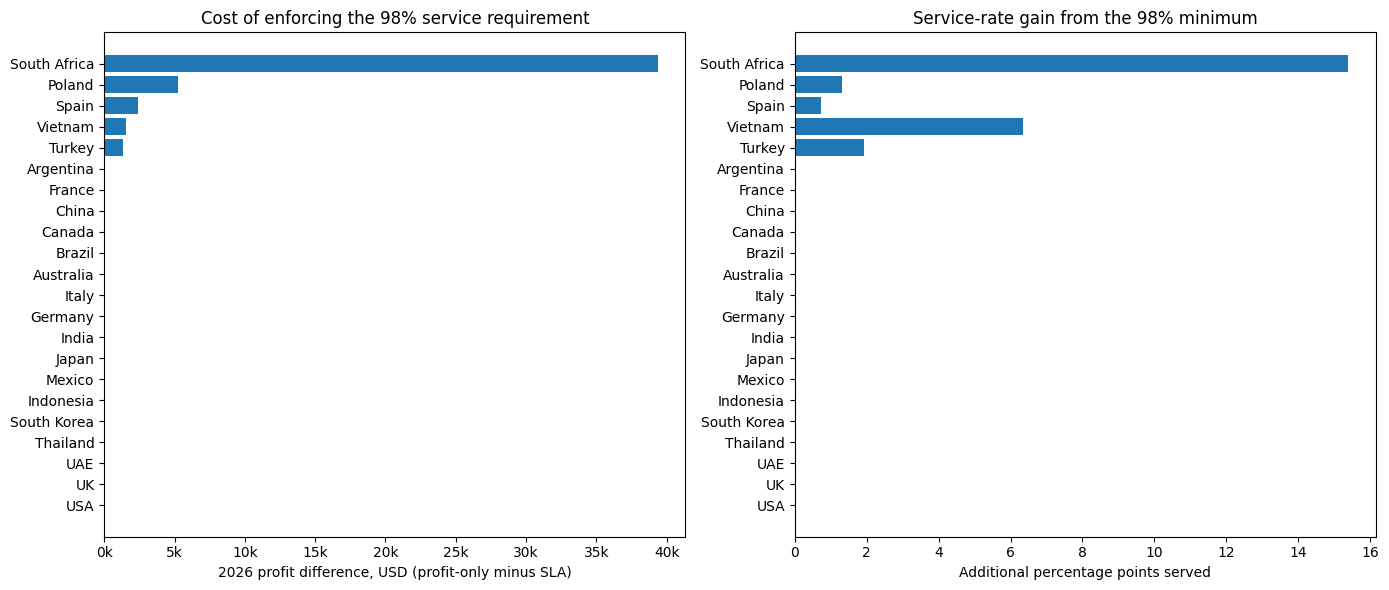

In [14]:
all_country_optimized = []
all_country_plans = []
all_country_solver_audits = []
if OPTIMIZE_ALL_COUNTRIES:
    for country in countries.Country:
        for label, min_rate in [('Profit only', None), ('Profit with SLA', MIN_ANNUAL_SERVICE_RATE)]:
            plan, detail, audit, meta = simulate_optimized_plan(country, min_rate)
            detail['Optimization_Mode'] = label
            all_country_plans.append(plan)
            all_country_optimized.append(detail)
            all_country_solver_audits.append({'Mode': label, **meta})
    all_country_detail = pd.concat(all_country_optimized, ignore_index=True)
    country_metrics = (all_country_detail
        .groupby(['Country', 'Optimization_Mode'], as_index=False)
        .agg(Profit_USD=('Modeled_Profit_USD', 'sum'),
             Revenue_USD=('Modeled_Revenue_USD', 'sum'),
             Staffing_Cost_USD=('Total_Staffing_Cost_USD', 'sum'),
             Arrivals=('Arrivals', 'sum'),
             Served=('Served', 'sum'),
             Hires=('Hires_Ordered', 'sum'),
             Releases=('Releases', 'sum')))
    country_metrics['Service_Rate_%'] = (100*country_metrics.Served/country_metrics.Arrivals).round(2)
    full_summary = (country_metrics.groupby('Optimization_Mode', as_index=False)
        .agg(Model_Profit_USD=('Profit_USD','sum'),
             Model_Revenue_USD=('Revenue_USD','sum'),
             Model_Cost_USD=('Staffing_Cost_USD','sum'),
             Arrivals=('Arrivals','sum'), Served=('Served','sum'), Hires=('Hires','sum')))
    full_summary['Aggregate_Service_Rate_%'] = (100*full_summary.Served/full_summary.Arrivals).round(3)
    print('All-country results: 22 country-specific optimized plans per objective (44 MILPs)')
    display(full_summary.round(2))
    print('Country-level results:')
    display(country_metrics[['Country','Optimization_Mode','Hires','Profit_USD','Service_Rate_%']]
            .sort_values(['Country','Optimization_Mode']).round(2))
else:
    print('Optional 22-country optimization OFF. Set OPTIMIZE_ALL_COUNTRIES=True in Section 6.')

if OPTIMIZE_ALL_COUNTRIES:
    # For a live classroom demo: reveal the profit/service trade-off by country.
    from matplotlib.ticker import FuncFormatter
    pivot = country_metrics.pivot(index='Country', columns='Optimization_Mode', values=['Profit_USD','Service_Rate_%'])
    country_order = (pivot['Profit_USD']['Profit only'] - pivot['Profit_USD']['Profit with SLA']).sort_values(ascending=False).index
    lost_profit = (pivot['Profit_USD']['Profit only'] - pivot['Profit_USD']['Profit with SLA']).loc[country_order]
    service_gain = (pivot['Service_Rate_%']['Profit with SLA'] - pivot['Service_Rate_%']['Profit only']).loc[country_order]
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].barh(country_order[::-1], lost_profit.iloc[::-1])
    axes[0].set_title('Cost of enforcing the 98% service requirement')
    axes[0].set_xlabel('2026 profit difference, USD (profit-only minus SLA)')
    axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:,.0f}k'))
    axes[1].barh(country_order[::-1], service_gain.iloc[::-1])
    axes[1].set_title('Service-rate gain from the 98% minimum')
    axes[1].set_xlabel('Additional percentage points served')
    plt.tight_layout()
    plt.show()


### 6c · STEP 4 - Comparing each country against current staff

This compares optimized results (SLA and Profit) with “keep current staff” for all countries. A positive profit improvement means the optimized plan better the baseline.


In [15]:
# Baseline
baseline_runs = []
for country in countries.Country:
    detail, audit = simulate_game(country, no_change_decider, 'Keep current staff')
    baseline_runs.append(detail)

baseline_detail = pd.concat(baseline_runs, ignore_index=True)

baseline_summary = (baseline_detail.groupby('Country', as_index=False)
    .agg(Baseline_Profit=('Modeled_Profit_USD', 'sum'),
         Baseline_Cost=('Total_Staffing_Cost_USD', 'sum'),
         Baseline_Served=('Served', 'sum'),
         Baseline_Arrivals=('Arrivals', 'sum')))

baseline_summary['Baseline_Service_%'] = (100 * baseline_summary.Baseline_Served
    / baseline_summary.Baseline_Arrivals.replace(0, np.nan))

# Compare both modes (profit and SLA) with the same country baseline
comparison = country_metrics.merge(baseline_summary, on='Country', validate='many_to_one')
assert (comparison.Arrivals == comparison.Baseline_Arrivals).all()

comparison['Profit_Improvement'] = comparison.Profit_USD - comparison.Baseline_Profit
comparison['Additional_Cost'] = comparison.Staffing_Cost_USD - comparison.Baseline_Cost
comparison['Additional_Served'] = comparison.Served - comparison.Baseline_Served
comparison['Optimized_Service_%'] = 100 * comparison.Served / comparison.Arrivals.replace(0, np.nan)
comparison['Service_Improvement_pp'] = comparison['Optimized_Service_%'] - comparison['Baseline_Service_%']

for mode in ['Profit only', 'Profit with SLA']:
    print(mode, 'vs Keep current staff')
    display(comparison[comparison.Optimization_Mode == mode][[
        'Country', 'Baseline_Profit', 'Profit_USD', 'Profit_Improvement',
        'Additional_Cost', 'Additional_Served',
        'Baseline_Service_%', 'Optimized_Service_%'
    ]].sort_values('Profit_Improvement', ascending=False).round(2))

Profit only vs Keep current staff


,Country,Baseline_Profit,Profit_USD,Profit_Improvement,Additional_Cost,Additional_Served,Baseline_Service_%,Optimized_Service_%
14,India,24512313.28,31720929.53,7208616.25,636910.04,4171,71.12,100.00
4,Brazil,14481671.02,16780721.81,2299050.79,376020.67,1187,79.26,100.00
42,Vietnam,1115836.85,3379303.83,2263466.98,561171.04,3059,29.05,91.81
8,China,19411561.52,19825700.17,414138.65,104571.28,408,92.97,100.00
40,USA,45801461.49,46079357.09,277895.60,377464.99,405,96.87,99.97
26,South Africa,639603.82,888367.44,248763.62,155511.81,603,62.63,82.80
20,Japan,11405707.21,11498486.76,92779.55,195537.60,318,93.58,98.34
6,Canada,8139819.87,8170431.40,30611.53,105430.27,140,95.95,98.92
30,Spain,2846015.27,2853531.03,7515.76,83407.87,200,91.86,97.40
28,South Korea,3778288.71,3783472.44,5183.73,28381.96,58,98.47,100.00


Profit with SLA vs Keep current staff


,Country,Baseline_Profit,Profit_USD,Profit_Improvement,Additional_Cost,Additional_Served,Baseline_Service_%,Optimized_Service_%
15,India,24512313.28,31720929.53,7208616.25,636910.04,4171,71.12,100.00
5,Brazil,14481671.02,16780721.81,2299050.79,376020.67,1187,79.26,100.00
43,Vietnam,1115836.85,3377750.04,2261913.18,607423.04,3369,29.05,98.17
9,China,19411561.52,19825700.17,414138.65,104571.28,408,92.97,100.00
41,USA,45801461.49,46079357.09,277895.60,377464.99,405,96.87,99.97
27,South Africa,639603.82,848998.36,209394.53,282598.59,1063,62.63,98.19
21,Japan,11405707.21,11498486.76,92779.55,195537.60,318,93.58,98.34
7,Canada,8139819.87,8170431.40,30611.53,105430.27,140,95.95,98.92
29,South Korea,3778288.71,3783472.44,5183.73,28381.96,58,98.47,100.00
31,Spain,2846015.27,2851101.08,5085.81,94566.49,226,91.86,98.12


### 6D · STEP 4 - *Overall* Comparison for All Countries with 3 different methods

In [16]:
#Combine all countries into one summary
overall = (comparison.groupby('Optimization_Mode', as_index=False)
    .agg(Profit=('Profit_USD', 'sum'),
         Staffing_Cost=('Staffing_Cost_USD', 'sum'),
         Customers=('Arrivals', 'sum'),
         Served=('Served', 'sum')))

overall = overall.rename(columns={'Optimization_Mode': 'Mode'})

baseline_row = pd.DataFrame([{
    'Mode': 'Keep current staff',
    'Profit': baseline_summary.Baseline_Profit.sum(),
    'Staffing_Cost': baseline_summary.Baseline_Cost.sum(),
    'Customers': baseline_summary.Baseline_Arrivals.sum(),
    'Served': baseline_summary.Baseline_Served.sum()
}])

overall = pd.concat([baseline_row, overall], ignore_index=True)

# Calculat service and profit improvement over baseline
overall['Service_%'] = 100 * overall.Served / overall.Customers.replace(0, np.nan)
overall['Profit_Improvement'] = overall.Profit - baseline_row.Profit.iloc[0]

print('All-country comparison:')
display(overall.round(2))

All-country comparison:


,Mode,Profit,Staffing_Cost,Customers,Served,Service_%,Profit_Improvement
0,Keep current staff,1.726184e+08,57236501.00,106171,94269,88.79,0.00
1,Profit only,1.854664e+08,59860908.52,106171,104818,98.73,12848022.46
2,Profit with SLA,1.854165e+08,60076651.19,106171,105694,99.55,12798079.62


### 6E · STEP 4 - Monthly Hiring Table and Export

In [17]:
# Combine monthly plans for both optimization modes
monthly_plan = pd.concat(all_country_plans, ignore_index=True)

monthly_plan = monthly_plan[['Country', 'Mode', 'Month', 'New_Hires', 'Releases', 'Projected_Active_Flexible', 'Projected_Arrivals']].sort_values(['Country', 'Mode', 'Month'])

# Countries as rows and months as columns
# Display each mode in CSV format
for mode in monthly_plan.Mode.unique():
    print(mode)
    table = monthly_plan[monthly_plan.Mode == mode].reset_index(drop=True)

    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(table)

Profit max (98% service minimum)


,Country,Mode,Month,New_Hires,Releases,Projected_Active_Flexible,Projected_Arrivals
0,Argentina,Profit max (98% service minimum),1,0,0,0,71
1,Argentina,Profit max (98% service minimum),2,0,0,0,68
2,Argentina,Profit max (98% service minimum),3,0,0,0,69
3,Argentina,Profit max (98% service minimum),4,0,0,0,69
4,Argentina,Profit max (98% service minimum),5,0,0,0,68
5,Argentina,Profit max (98% service minimum),6,0,0,0,59
6,Argentina,Profit max (98% service minimum),7,0,0,0,64
7,Argentina,Profit max (98% service minimum),8,0,0,0,61
8,Argentina,Profit max (98% service minimum),9,0,0,0,75
9,Argentina,Profit max (98% service minimum),10,0,0,0,101


Profit max (no service minimum)


,Country,Mode,Month,New_Hires,Releases,Projected_Active_Flexible,Projected_Arrivals
0,Argentina,Profit max (no service minimum),1,0,0,0,71
1,Argentina,Profit max (no service minimum),2,0,0,0,68
2,Argentina,Profit max (no service minimum),3,0,0,0,69
3,Argentina,Profit max (no service minimum),4,0,0,0,69
4,Argentina,Profit max (no service minimum),5,0,0,0,68
5,Argentina,Profit max (no service minimum),6,0,0,0,59
6,Argentina,Profit max (no service minimum),7,0,0,0,64
7,Argentina,Profit max (no service minimum),8,0,0,0,61
8,Argentina,Profit max (no service minimum),9,0,0,0,75
9,Argentina,Profit max (no service minimum),10,0,0,0,101


In [18]:
# Separate the 98% SLA plan and profit-only plan
sla_plan = monthly_plan[monthly_plan.Mode == 'Profit max (98% service minimum)']
profit_plan = monthly_plan[monthly_plan.Mode == 'Profit max (no service minimum)']


sla_plan.to_csv('staffing_plan_98_sla.csv', index=False)
profit_plan.to_csv('staffing_plan_profit_only.csv', index=False)

from google.colab import files
files.download('staffing_plan_98_sla.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7a. STEP 5 - Prepare Scenarios and Staffing Plans

Save a copy of the original inputs, define demand multipliers of 0.80, 1.00, and 1.20, and separate the profit-only and 98% SLA plans. Check that each plan includes every country and all 12 months.

In [20]:
# Save the original inputs and staffing plans
original_inputs = inputs.copy(deep=True)

scenarios = {
    'Low demand (-20%)': 0.80,
    'Base demand': 1.00,
    'High demand (+20%)': 1.20
}

profit_plans = monthly_plan[monthly_plan.Mode == 'Profit max (no service minimum)'].copy()
sla_plans = monthly_plan[monthly_plan.Mode == 'Profit max (98% service minimum)'].copy()

for plan in [profit_plans, sla_plans]:
    assert set(plan.Country) == set(countries.Country), 'Missing countries.'
    assert not plan.duplicated(['Country', 'Month']).any(), 'Duplicate months.'
    assert plan.groupby('Country').Month.apply(
        lambda months: set(months) == set(range(1, 13))
    ).all(), 'Missing months.'

## 7b. STEP 5 - Run the Scenario Simulations

Run all three modes for every country under low, base, and high demand. Keep hiring and releases unchanged.

In [21]:
scenario_runs = []

# Change demand while keeping staffing decisions fixed
try:
    for scenario, multiplier in scenarios.items():
        inputs = original_inputs.copy(deep=True)
        inputs['Forecast_Eligible_Signups'] = (
            inputs.Forecast_Eligible_Signups * multiplier
        )

        for country in countries.Country:
            profit_plan = profit_plans[
                profit_plans.Country == country
            ].sort_values('Month')

            sla_plan = sla_plans[
                sla_plans.Country == country
            ].sort_values('Month')

            policies = {
                'Keep current staff': no_change_decider,
                'Profit only': policy_from_plan(profit_plan),
                'Profit with SLA': policy_from_plan(sla_plan)
            }

            for mode, policy in policies.items():
                detail, audit = simulate_game(
                    country, policy, mode,
                    enforce_capacity_guardrail=False
                )

                # Confirm that the simulator applied the original plan
                if mode == 'Keep current staff':
                    assert (detail.Hires_Ordered == 0).all()
                    assert (detail.Releases == 0).all()
                else:
                    plan = profit_plan if mode == 'Profit only' else sla_plan
                    assert np.array_equal(
                        detail.Hires_Ordered.to_numpy(), plan.New_Hires.to_numpy()
                    )
                    assert np.array_equal(
                        detail.Releases.to_numpy(), plan.Releases.to_numpy()
                    )

                assert not detail.Action_Source.eq('SAFE_FALLBACK_NOT_LLM').any()

                detail['Scenario'] = scenario
                detail['Mode'] = mode
                scenario_runs.append(detail)

        print('Completed:', scenario)

finally:
    inputs = original_inputs.copy(deep=True)

scenario_detail = pd.concat(scenario_runs, ignore_index=True)

Completed: Low demand (-20%)
Completed: Base demand
Completed: High demand (+20%)


## 7c. STEP 5 - Sensitivy Analysis Results by Country

Summarize annual profit, staffing costs, customers served, abandonment, and year-end backlog. Display results alphabetically by country, with low, base, and high demand grouped together within each country.

In [26]:
# Summarize annual results
scenario_country = (scenario_detail.sort_values(['Country', 'Scenario', 'Mode', 'Month'])
    .groupby(['Country', 'Scenario', 'Mode'], as_index=False)
    .agg(Profit=('Modeled_Profit_USD', 'sum'), Staffing_Cost=('Total_Staffing_Cost_USD', 'sum'),
         Customers=('Arrivals', 'sum'), Served=('Served', 'sum'), Abandoned=('Abandoned', 'sum'),
         Year_End_Backlog=('Backlog_End', 'last')))

scenario_country['Service_%'] = 100 * scenario_country.Served / scenario_country.Customers.replace(0, np.nan)
scenario_country['Not_Served'] = scenario_country.Customers - scenario_country.Served
assert (scenario_country.Not_Served == scenario_country.Abandoned + scenario_country.Year_End_Backlog).all()

# Show each country in low, base, high demand order
scenario_country['Scenario'] = pd.Categorical(scenario_country.Scenario, categories=['Low demand (-20%)', 'Base demand', 'High demand (+20%)'], ordered=True)
scenario_country = scenario_country.sort_values(['Country', 'Scenario', 'Mode']).reset_index(drop=True)

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(scenario_country.round(2))

,Country,Scenario,Mode,Profit,Staffing_Cost,Customers,Served,Abandoned,Year_End_Backlog,Service_%,Not_Served
0,Argentina,Low demand (-20%),Keep current staff,-341539.27,747480.00,722,722,0,0,100.00,0
1,Argentina,Low demand (-20%),Profit only,-341539.27,747480.00,722,722,0,0,100.00,0
2,Argentina,Low demand (-20%),Profit with SLA,-341539.27,747480.00,722,722,0,0,100.00,0
3,Argentina,Base demand,Keep current staff,-240981.73,747480.00,902,902,0,0,100.00,0
4,Argentina,Base demand,Profit only,-240981.73,747480.00,902,902,0,0,100.00,0
5,Argentina,Base demand,Profit with SLA,-240981.73,747480.00,902,902,0,0,100.00,0
6,Argentina,High demand (+20%),Keep current staff,-139960.38,747480.00,1083,1083,0,0,100.00,0
7,Argentina,High demand (+20%),Profit only,-139960.38,747480.00,1083,1083,0,0,100.00,0
8,Argentina,High demand (+20%),Profit with SLA,-139960.38,747480.00,1083,1083,0,0,100.00,0
9,Australia,Low demand (-20%),Keep current staff,3340522.83,3915450.00,3709,3709,0,0,100.00,0


## 7d. STEP 5 - Compare Overall Results

Combine results across all countries and calculate each mode profit improvement against the baseline under the diffrent demand.

In [23]:
# Combine countries and compare against the baseline in the same scenario
scenario_summary = (scenario_country
    .groupby(['Scenario', 'Mode'], as_index=False)
    .agg(Profit=('Profit', 'sum'),
         Staffing_Cost=('Staffing_Cost', 'sum'),
         Customers=('Customers', 'sum'),
         Served=('Served', 'sum'),
         Abandoned=('Abandoned', 'sum'),
         Year_End_Backlog=('Year_End_Backlog', 'sum')))

scenario_summary['Service_%'] = (
    100 * scenario_summary.Served
    / scenario_summary.Customers.replace(0, np.nan)
)

scenario_baseline = scenario_summary[
    scenario_summary.Mode == 'Keep current staff'
][['Scenario', 'Profit']].rename(columns={'Profit': 'Baseline_Profit'})

scenario_summary = scenario_summary.merge(
    scenario_baseline, on='Scenario', validate='many_to_one'
)

scenario_summary['Profit_Improvement'] = (
    scenario_summary.Profit - scenario_summary.Baseline_Profit
)

for scenario in scenarios:
    print(scenario)
    display(scenario_summary[
        scenario_summary.Scenario == scenario
    ][[
        'Mode', 'Profit', 'Staffing_Cost', 'Customers', 'Served',
        'Service_%', 'Abandoned', 'Year_End_Backlog', 'Profit_Improvement'
    ]].reset_index(drop=True).round(2))

Low demand (-20%)


,Mode,Profit,Staffing_Cost,Customers,Served,Service_%,Abandoned,Year_End_Backlog,Profit_Improvement
0,Keep current staff,1.352906e+08,57236501.00,84934,80117,94.33,1309,3508,0.00
1,Profit only,1.366742e+08,59860908.52,84934,84372,99.34,0,562,1383607.60
2,Profit with SLA,1.365445e+08,60076651.19,84934,84934,100.00,0,0,1253947.69


Base demand


,Mode,Profit,Staffing_Cost,Customers,Served,Service_%,Abandoned,Year_End_Backlog,Profit_Improvement
0,Keep current staff,1.726184e+08,57236501.00,106171,94269,88.79,2495,9407,0.00
1,Profit only,1.854664e+08,59860908.52,106171,104818,98.73,0,1353,12848022.46
2,Profit with SLA,1.854165e+08,60076651.19,106171,105694,99.55,0,477,12798079.62


High demand (+20%)


,Mode,Profit,Staffing_Cost,Customers,Served,Service_%,Abandoned,Year_End_Backlog,Profit_Improvement
0,Keep current staff,2.063831e+08,57236501.00,127400,106655,83.72,5918,14827,0.00
1,Profit only,2.197495e+08,59860908.52,127400,117415,92.16,75,9910,13366382.86
2,Profit with SLA,2.197031e+08,60076651.19,127400,118295,92.85,0,9105,13320064.06


## EXPORTING CSV

In [31]:
# Save the overall and country-level scenario results
scenario_summary.to_csv('demand_sensitivily_analysis_summary.csv', index=False)
scenario_country.to_csv('demand_sensitivily_analysis_results.csv', index=False)

from google.colab import files
files.download('demand_sensitivily_analysis_summary.csv')
files.download('demand_sensitivily_analysis_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 5 — How to interpret / present the findings

**Demand testing:** For Step 5, Step 4 staffing plans were evaluated under demand 20% below forecast, equal to forecast, and 20% above forecast. Monthly hiring and release decisions remained fixed. Compare each optimized mode with keeping current staff under the same demand scenario.

**3 Scenarios:**

 - **Low demand:** Both modes is better the baseline, adding **1.25–1.38 million** in profit. The SLA plan serves **100%** of customers.
 - **Base demand:** Both modes add approximately **12.8 million** in profit. SLA achieves **99.55% service**, compared with **98.73%** for profit-only.
 - **High demand:** Both modes add approximately **13.3 million** in profit, but service falls below 98%. SLA achieves **92.85%**, leaving **9,105 customers waiting** at year-end.

**Insights::** Compared with profit-only, Profit with SLA delivers better customer service with only a small profit reduction, but needs additional capacity if demand rises 20%.

**Output:** `demand_sensitivily_analysis_summary.csv`, `demand_sensitivily_analysis_results.csv`
